In [ ]:
import pandas as pd

df = pd.read_csv("/content/finale_updated.csv")

In [ ]:
!nvidia-smi


Tue Nov  4 14:16:12 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
df.shape

(180846, 14)

In [ ]:
df["Prediction"].unique()

array(['SS', 'A', 'S', 'Normal', nan], dtype=object)

In [ ]:
df = df.dropna(subset=['Prediction'])

# (Optional) verify cleanup
print("Remaining rows:", df.shape[0])
print("NaN values in Prediction:", df['Prediction'].isna().sum())

Remaining rows: 168638
NaN values in Prediction: 0


In [ ]:
df

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,50.000000,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,500.0,5.0,A,Bonet,5061.0,SS
1,40.000000,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,504.0,8.0,A,Bonet,5061.0,SS
2,30.000000,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,508.0,7.0,A,Bonet,5061.0,SS
3,20.000000,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,512.0,15.0,A,Bonet,5061.0,SS
4,57.000000,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,516.0,9.0,A,Bonet,5061.0,SS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
168633,0.000000,TCP,FIN,NaN,2.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal
168634,0.000000,ICMP,SYN,NaN,3.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal
168635,0.000000,UDP,SYN,NaN,1.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal
168636,0.000000,TCP,ACK,NaN,1.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal


In [ ]:
df_normal = df[df['Prediction'] == 'Normal']

In [ ]:
df_abnormal = df[df['Prediction'] != 'Normal']

In [ ]:
df_normal

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
149043,2318.019030,ICMP,SYN,NaN,3.0,0,0,0.0,0.0,0.0,0,NaN,0.0,Normal
149044,0.000000,UDP,ACK,NaN,3.0,104.18.32.47,192.168.0.103,0.0,0.0,0.0,104.18.32.47,NaN,443.0,Normal
149045,1501.022267,TCP,SYN,NaN,3.0,104.18.39.21,192.168.0.103,0.0,0.0,0.0,104.18.39.21,NaN,443.0,Normal
149046,783.037846,TCP,ACK,NaN,1.0,104.18.39.21,192.168.0.103,0.0,0.0,0.0,104.18.39.21,NaN,443.0,Normal
149047,109.982108,TCP,FIN,NaN,2.0,104.208.16.89,192.168.0.103,0.0,0.0,0.0,104.208.16.89,NaN,443.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
168633,0.000000,TCP,FIN,NaN,2.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal
168634,0.000000,ICMP,SYN,NaN,3.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal
168635,0.000000,UDP,SYN,NaN,1.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal
168636,0.000000,TCP,ACK,NaN,1.0,98.90.219.42,192.168.1.8,0.0,0.0,0.0,98.90.219.42,NaN,443.0,Normal


In [ ]:
df_abnormal

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,50.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,500.0,5.0,A,Bonet,5061.0,SS
1,40.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,504.0,8.0,A,Bonet,5061.0,SS
2,30.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,508.0,7.0,A,Bonet,5061.0,SS
3,20.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,512.0,15.0,A,Bonet,5061.0,SS
4,57.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,516.0,9.0,A,Bonet,5061.0,SS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149038,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1010.0,1590.0,3340.0,A,Scan,5062.0,A
149039,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1014.0,1596.0,3351.0,A,Scan,5062.0,A
149040,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1018.0,1602.0,3362.0,A,Scan,5062.0,A
149041,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1022.0,1608.0,3373.0,A,Scan,5062.0,A


In [ ]:
df.shape

(168638, 14)

In [ ]:
df_normal.shape

(19595, 14)

In [ ]:
df_abnormal.shape

(149043, 14)

In [ ]:
# Save the cleaned dataframe
df_normal.to_csv("df_normal.csv", index=False)

# To download in Colab
from google.colab import files
files.download("df_normal.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
data = df_normal

In [ ]:
data['Prediction'].unique()

array(['Normal'], dtype=object)

In [ ]:
data = data.dropna(how='all')

data['Threats'] = data['Threats'].str.replace('Bonet', 'Botnet')

objList = data.select_dtypes(include = "object").columns
print (objList)

from sklearn.preprocessing import LabelEncoder

label_encoders = {}  # store encoders per column

for feat in objList:
    le = LabelEncoder()
    data[feat] = le.fit_transform(data[feat].astype(str))
    label_encoders[feat] = le   # save encoder

print(data.info())

# ✅ To see mapping for Prediction column:
print("Mapping for Prediction column:")
print(dict(zip(label_encoders["Prediction"].classes_,
               label_encoders["Prediction"].transform(label_encoders["Prediction"].classes_))))




Index(['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress',
       'Threats', 'Prediction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 19595 entries, 149043 to 168637
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Time           19595 non-null  float64
 1   Protcol        19595 non-null  int64  
 2   Flag           19595 non-null  int64  
 3   Family         19595 non-null  int64  
 4   Clusters       19595 non-null  float64
 5   SeddAddress    19595 non-null  int64  
 6   ExpAddress     19595 non-null  int64  
 7   BTC            19595 non-null  float64
 8   USD            19595 non-null  float64
 9   Netflow_Bytes  19595 non-null  float64
 10  IPaddress      19595 non-null  int64  
 11  Threats        19595 non-null  int64  
 12  Port           19595 non-null  float64
 13  Prediction     19595 non-null  int64  
dtypes: float64(6), int64(8)
memory usage: 2.7 MB
Non

In [ ]:
data.shape

(19595, 14)

In [ ]:
data

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
149043,2318.019030,0,2,0,3.0,0,0,0.0,0.0,0.0,0,0,0.0,0
149044,0.000000,2,0,0,3.0,5,89,0.0,0.0,0.0,5,0,443.0,0
149045,1501.022267,1,2,0,3.0,7,89,0.0,0.0,0.0,7,0,443.0,0
149046,783.037846,1,0,0,1.0,7,89,0.0,0.0,0.0,7,0,443.0,0
149047,109.982108,1,1,0,2.0,9,89,0.0,0.0,0.0,9,0,443.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
168633,0.000000,1,1,0,2.0,302,94,0.0,0.0,0.0,302,0,443.0,0
168634,0.000000,0,2,0,3.0,302,94,0.0,0.0,0.0,302,0,443.0,0
168635,0.000000,2,2,0,1.0,302,94,0.0,0.0,0.0,302,0,443.0,0
168636,0.000000,1,0,0,1.0,302,94,0.0,0.0,0.0,302,0,443.0,0


Epoch 1/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - loss: 0.3554 - val_loss: 0.0083
Epoch 2/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0060 - val_loss: 0.0030
Epoch 3/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0026 - val_loss: 0.0020
Epoch 4/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0022 - val_loss: 0.0010
Epoch 5/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 6/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0011 - val_loss: 7.8276e-04
Epoch 7/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0011 - val_loss: 8.8366e-04
Epoch 8/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 7.1165e-04 - val_loss: 5.5889e-04
Epoch 9/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.1490e-04 - val_loss: 8.2633e-04
Epoch 10/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.8458e-04 - val_loss: 4.8366e-04
Epoch 11/100
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6.4249e-04 - val_loss: 4.0846e-04
Epoch 12/100
62/62 ━━

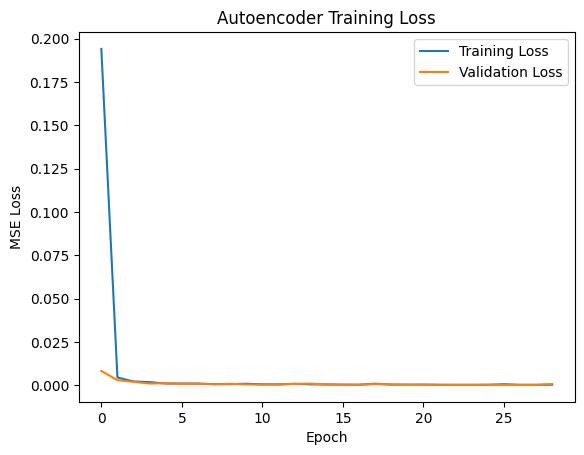

Anomaly Threshold: 0.0022230703030121824
✅ Model and Scaler saved successfully!


In [ ]:
# --------------------------
# 1. Import libraries
# --------------------------
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# --------------------------
# 2. Scale features
# --------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

# --------------------------
# 3. Build the deep autoencoder
# --------------------------
input_dim = X_scaled.shape[1]
input_layer = Input(shape=(input_dim,))

# Encoder
encoded = Dense(128, activation='relu')(input_layer)
encoded = Dense(64, activation='relu')(encoded)
bottleneck = Dense(32, activation='relu')(encoded)

# Decoder
decoded = Dense(64, activation='relu')(bottleneck)
decoded = Dense(128, activation='relu')(decoded)
output_layer = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(inputs=input_layer, outputs=output_layer)
autoencoder.compile(optimizer='adam', loss='mse')

# --------------------------
# 4. Train with Early Stopping
# --------------------------
es = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)

history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=100,
    batch_size=256,
    shuffle=True,
    validation_split=0.2,
    callbacks=[es],
    verbose=1
)

# --------------------------
# 5. Evaluate reconstruction error
# --------------------------
reconstructed = autoencoder.predict(X_scaled)
mse = np.mean(np.power(X_scaled - reconstructed, 2), axis=1)
print("Average MSE (Normal Data):", np.mean(mse))

# --------------------------
# 6. Visualize training loss
# --------------------------
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

# --------------------------
# 7. Set a threshold for anomaly detection
# --------------------------
dae_threshold = np.mean(mse) + 3*np.std(mse)
print("Anomaly Threshold:", dae_threshold)

# --------------------------
# 8. Save the model and scaler
# --------------------------
autoencoder.save("deep_autoencoder_model.h5")
import joblib
joblib.dump(scaler, "scaler.pkl")

print("✅ Model and Scaler saved successfully!")

# --------------------------
# 9. To load later elsewhere
# --------------------------
# from tensorflow.keras.models import load_model
# import joblib
# autoencoder = load_model("deep_autoencoder_model.h5")
# scaler = joblib.load("scaler.pkl")


In [ ]:
print("Reconstruction Error Threshold:", dae_threshold)

# Final “accuracy” proxy: how well it reconstructs normal samples
good_recon = np.sum(mse < dae_threshold)
accuracy = good_recon / len(mse)
print("Final Reconstruction Accuracy: {:.2f}%".format(accuracy * 100))

Reconstruction Error Threshold: 0.0022230703030121824
Final Reconstruction Accuracy: 99.17%


In [ ]:
check_Dae = df_abnormal

In [ ]:
def preprocessing(data):

    data = data.dropna(how='all')

    data['Threats'] = data['Threats'].str.replace('Bonet', 'Botnet')

    objList = data.select_dtypes(include = "object").columns
    print (objList)

    from sklearn.preprocessing import LabelEncoder

    label_encoders = {}  # store encoders per column

    for feat in objList:
        le = LabelEncoder()
        data[feat] = le.fit_transform(data[feat].astype(str))
        label_encoders[feat] = le   # save encoder

    print(data.info())

    return data

In [ ]:
check_Dae

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,50.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,500.0,5.0,A,Bonet,5061.0,SS
1,40.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,504.0,8.0,A,Bonet,5061.0,SS
2,30.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,508.0,7.0,A,Bonet,5061.0,SS
3,20.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,512.0,15.0,A,Bonet,5061.0,SS
4,57.0,TCP,A,WannaCry,1.0,1DA11mPS,1BonuSr7,1.0,516.0,9.0,A,Bonet,5061.0,SS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149038,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1010.0,1590.0,3340.0,A,Scan,5062.0,A
149039,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1014.0,1596.0,3351.0,A,Scan,5062.0,A
149040,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1018.0,1602.0,3362.0,A,Scan,5062.0,A
149041,33.0,UDP,AP,TowerWeb,3.0,1AEoiHYZ,1SYSTEMQ,1022.0,1608.0,3373.0,A,Scan,5062.0,A


In [ ]:
check_Dae = preprocessing(check_Dae)

Index(['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress',
       'Threats', 'Prediction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 149043 entries, 0 to 149042
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Time           149043 non-null  float64
 1   Protcol        149043 non-null  int64  
 2   Flag           149043 non-null  int64  
 3   Family         149043 non-null  int64  
 4   Clusters       149043 non-null  float64
 5   SeddAddress    149043 non-null  int64  
 6   ExpAddress     149043 non-null  int64  
 7   BTC            149043 non-null  float64
 8   USD            149043 non-null  float64
 9   Netflow_Bytes  149043 non-null  float64
 10  IPaddress      149043 non-null  int64  
 11  Threats        149043 non-null  int64  
 12  Port           149043 non-null  float64
 13  Prediction     149043 non-null  int64  
dtypes: float64(6), int64(8)
memory usage

In [ ]:
def DAE_opinion(check_Dae):
  from sklearn.metrics import mean_squared_error
  import numpy as np
  import pandas as pd

  # Ensure your check_Dae is a DataFrame or NumPy array
  X_test_scaled = scaler.transform(check_Dae)

  # Reconstruct all packets
  reconstructed = autoencoder.predict(X_test_scaled)

  # Compute reconstruction error for each packet
  mse_errors = np.mean(np.square(X_test_scaled - reconstructed), axis=1)

  # Set threshold (you can tune this using normal data stats)
  threshold = 0.005  # Replace with dynamic threshold if available

  # Classify packets
  labels = np.where(mse_errors > threshold, "Anomalous", "Normal")

  # Create results DataFrame
  results_df = pd.DataFrame({
      "Packet_ID": np.arange(len(mse_errors)),
      "Reconstruction_Error": mse_errors,
      "Classification": labels
  })

  # Show summary
  print(results_df.head())
  print("\n🔹 Total Packets:", len(results_df))
  print("✅ Normal Packets:", (labels == "Normal").sum())
  print("⚠️ Anomalous Packets:", (labels == "Anomalous").sum())


In [ ]:
DAE_opinion(check_Dae)

4658/4658 ━━━━━━━━━━━━━━━━━━━━ 7s 1ms/step
   Packet_ID  Reconstruction_Error Classification
0          0          19375.322599      Anomalous
1          1          19687.178091      Anomalous
2          2          20000.793807      Anomalous
3          3          20321.433094      Anomalous
4          4          20636.878965      Anomalous

🔹 Total Packets: 149043
✅ Normal Packets: 0
⚠️ Anomalous Packets: 149043


In [ ]:
df_normal_preproc = preprocessing(df_normal)

Index(['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress',
       'Threats', 'Prediction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 19595 entries, 149043 to 168637
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Time           19595 non-null  float64
 1   Protcol        19595 non-null  int64  
 2   Flag           19595 non-null  int64  
 3   Family         19595 non-null  int64  
 4   Clusters       19595 non-null  float64
 5   SeddAddress    19595 non-null  int64  
 6   ExpAddress     19595 non-null  int64  
 7   BTC            19595 non-null  float64
 8   USD            19595 non-null  float64
 9   Netflow_Bytes  19595 non-null  float64
 10  IPaddress      19595 non-null  int64  
 11  Threats        19595 non-null  int64  
 12  Port           19595 non-null  float64
 13  Prediction     19595 non-null  int64  
dtypes: float64(6), int64(8)
memory usage: 2.7 MB
Non

In [ ]:
DAE_opinion(df_normal_preproc)

613/613 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
   Packet_ID  Reconstruction_Error Classification
0          0              0.006849      Anomalous
1          1              0.000196         Normal
2          2              0.007257      Anomalous
3          3              0.005560      Anomalous
4          4              0.001391         Normal

🔹 Total Packets: 19595
✅ Normal Packets: 19464
⚠️ Anomalous Packets: 131


Device: cuda
Epoch 001 | Train MSE: 0.306580 | Val MSE: 0.295617
Epoch 002 | Train MSE: 0.279913 | Val MSE: 0.293862
Epoch 003 | Train MSE: 0.277667 | Val MSE: 0.293762
Epoch 004 | Train MSE: 0.276754 | Val MSE: 0.296652
Epoch 005 | Train MSE: 0.275899 | Val MSE: 0.295570
Epoch 006 | Train MSE: 0.274946 | Val MSE: 0.294738
Epoch 007 | Train MSE: 0.274593 | Val MSE: 0.291512
Epoch 008 | Train MSE: 0.273471 | Val MSE: 0.289358
Epoch 009 | Train MSE: 0.272908 | Val MSE: 0.291104
Epoch 010 | Train MSE: 0.271798 | Val MSE: 0.289147
Epoch 011 | Train MSE: 0.271871 | Val MSE: 0.286492
Epoch 012 | Train MSE: 0.269592 | Val MSE: 0.290745
Epoch 013 | Train MSE: 0.268290 | Val MSE: 0.293028
Epoch 014 | Train MSE: 0.267015 | Val MSE: 0.288586
Epoch 015 | Train MSE: 0.265688 | Val MSE: 0.279984
Epoch 016 | Train MSE: 0.263994 | Val MSE: 0.286726
Epoch 017 | Train MSE: 0.261504 | Val MSE: 0.284575
Epoch 018 | Train MSE: 0.260499 | Val MSE: 0.287800
Epoch 019 | Train MSE: 0.257719 | Val MSE: 0.287765

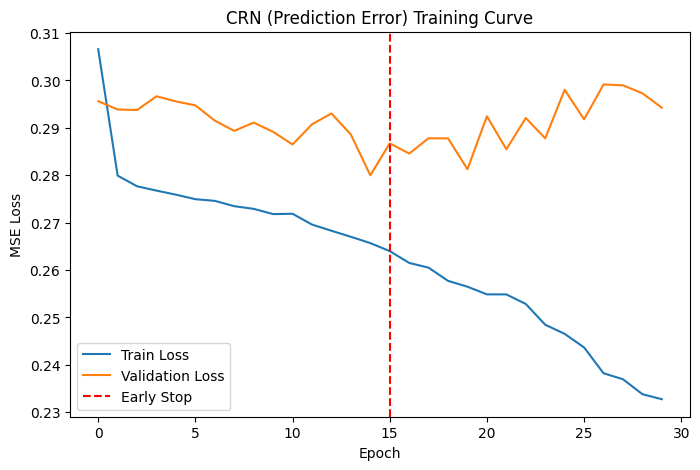

Prediction Error Threshold: 2.862347
CRN Accuracy on Normal Data: 99.73%
✅ CRN model, scaler, and metadata saved successfully to: models


'\nfrom pathlib import Path\nimport torch, joblib\nfrom model_def import LSTM_CRN  # or copy the class definition here\n\nMODEL_DIR = Path("./models")\nmeta = joblib.load(MODEL_DIR / "crn_meta.pkl")\nscaler = joblib.load(MODEL_DIR / "crn_scaler.pkl")\n\ncrn = LSTM_CRN(input_dim=meta[\'input_dim\'], hidden=256)\ncrn.load_state_dict(torch.load(MODEL_DIR / "crn_final.pth"))\ncrn.eval()\n\n# Now you can preprocess new data using scaler and pass sequences of length meta[\'seq_len\'] to crn.\n'

In [ ]:
# =======================================================
# 1. Imports & Device Setup
# =======================================================
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
import joblib

MODEL_DIR = Path("./models")
MODEL_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# =======================================================
# 2. Define CRN Model (LSTM-based predictor)
# =======================================================
class LSTM_CRN(nn.Module):
    def __init__(self, input_dim, hidden=128, n_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden, num_layers=n_layers, batch_first=True)
        self.fc = nn.Linear(hidden, input_dim)
    def forward(self, seq):
        out, _ = self.lstm(seq)
        last = out[:, -1, :]
        return self.fc(last)

# =======================================================
# 3. Prepare Sequence Data
# =======================================================
def create_sequences(X, seq_len=10):
    X_seq, Y_seq = [], []
    for i in range(len(X) - seq_len):
        X_seq.append(X[i:i+seq_len])
        Y_seq.append(X[i+seq_len])
    return np.array(X_seq), np.array(Y_seq)

# assume you have `X_scaled` (normal-only data)
SEQ_LEN = 10
X_seq, Y_seq = create_sequences(X_scaled, SEQ_LEN)

dataset = TensorDataset(torch.tensor(X_seq, dtype=torch.float32),
                        torch.tensor(Y_seq, dtype=torch.float32))

val_ratio = 0.1
n_val = int(len(dataset) * val_ratio)
n_train = len(dataset) - n_val
train_ds, val_ds = random_split(dataset, [n_train, n_val])

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=128, shuffle=False)

# =======================================================
# 4. Model, Optimizer, Loss
# =======================================================
input_dim = X_seq.shape[2]
crn = LSTM_CRN(input_dim=input_dim, hidden=256).to(device)
optimizer = torch.optim.Adam(crn.parameters(), lr=1e-3)
criterion = nn.MSELoss()

# =======================================================
# 5. Training with Early Stopping
# =======================================================
patience = 15
best_loss = float("inf")
wait = 0
max_epochs = 200
train_losses, val_losses = [], []

for epoch in range(max_epochs):
    # ---- Training ----
    crn.train()
    total_loss = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = crn(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)
    train_loss = total_loss / len(train_ds)

    # ---- Validation ----
    crn.eval()
    val_total = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = crn(xb)
            loss = criterion(pred, yb)
            val_total += loss.item() * xb.size(0)
    val_loss = val_total / len(val_ds)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoch {epoch+1:03d} | Train MSE: {train_loss:.6f} | Val MSE: {val_loss:.6f}")

    # ---- Early Stopping ----
    if val_loss < best_loss - 1e-6:
        best_loss = val_loss
        wait = 0
        torch.save(crn.state_dict(), MODEL_DIR / "crn_best.pth")
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

# =======================================================
# 6. Load Best Model
# =======================================================
crn.load_state_dict(torch.load(MODEL_DIR / "crn_best.pth"))
print("Loaded best CRN model with Val MSE:", best_loss)

# =======================================================
# 7. Plot Loss Curves
# =======================================================
plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.axvline(len(train_losses)-patience, color="red", linestyle="--", label="Early Stop")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("CRN (Prediction Error) Training Curve")
plt.legend()
plt.show()

# =======================================================
# 8. Compute Baseline Threshold
# =======================================================
crn.eval()
with torch.no_grad():
    preds = crn(torch.tensor(X_seq, dtype=torch.float32).to(device)).cpu().numpy()
mse_errors = np.mean((Y_seq - preds)**2, axis=1)
threshold = np.mean(mse_errors) + 3*np.std(mse_errors)
print(f"Prediction Error Threshold: {threshold:.6f}")
crn_threshold = threshold

accuracy = np.mean(mse_errors < threshold)
print(f"CRN Accuracy on Normal Data: {accuracy*100:.2f}%")

# =======================================================
# 9. Save Model, Scaler, and Config
# =======================================================
torch.save(crn.state_dict(), MODEL_DIR / "crn_final.pth")
joblib.dump(scaler, MODEL_DIR / "crn_scaler.pkl")

# Save model metadata (for reload)
meta = {
    "input_dim": input_dim,
    "seq_len": SEQ_LEN,
    "threshold": float(threshold)
}
joblib.dump(meta, MODEL_DIR / "crn_meta.pkl")

print("✅ CRN model, scaler, and metadata saved successfully to:", MODEL_DIR)

# =======================================================
# 10. Load and Reuse Later
# =======================================================
# Example snippet for reusing the model elsewhere:
"""
from pathlib import Path
import torch, joblib
from model_def import LSTM_CRN  # or copy the class definition here

MODEL_DIR = Path("./models")
meta = joblib.load(MODEL_DIR / "crn_meta.pkl")
scaler = joblib.load(MODEL_DIR / "crn_scaler.pkl")

crn = LSTM_CRN(input_dim=meta['input_dim'], hidden=256)
crn.load_state_dict(torch.load(MODEL_DIR / "crn_final.pth"))
crn.eval()

# Now you can preprocess new data using scaler and pass sequences of length meta['seq_len'] to crn.
"""


In [ ]:
crn_threshold

np.float64(2.862346637593289)

In [ ]:
# -----------------------------------
# 10. CRN opinion function (batch mode) - Fixed
# -----------------------------------
def crn_opinion_all(check_crn, seq_len=10):
    # Ensure DataFrame for scaler compatibility
    if not isinstance(check_crn, pd.DataFrame):
        check_crn = pd.DataFrame(check_crn, columns=getattr(scaler, "feature_names_in_", None))

    # Scale the input data
    X_scaled = scaler.transform(check_crn)

    crn.eval()
    mse_list, verdicts = [], []

    # Slide over packets, predict next-step
    with torch.no_grad():
        for i in range(len(X_scaled) - seq_len):
            seq = X_scaled[i:i+seq_len]
            true_next = X_scaled[i+seq_len]

            xb = torch.tensor(seq, dtype=torch.float32).unsqueeze(0).to(device)
            pred_next = crn(xb).cpu().numpy().squeeze()

            # --- Prediction error
            mse = np.mean((true_next - pred_next)**2)
            verdict = "Normal" if threshold is None or mse < threshold else "Anomalous"

            print(f"For index = {i}, verdict is {verdict}, MSE = {mse:.6f}")

            mse_list.append(mse)
            verdicts.append(verdict)

    # Build result table
    results_df = pd.DataFrame({
        "MSE_Error": mse_list,
        "Verdict": verdicts
    })

    print(f"\nTotal Packets Evaluated: {len(results_df)}")
    print(f"Anomalies Detected: {sum(results_df['Verdict']=='Anomalous')} packets")
    return results_df


In [ ]:
chech_crn = preprocessing(df_abnormal.head(100))

Index(['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress',
       'Threats', 'Prediction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 0 to 99
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Time           100 non-null    float64
 1   Protcol        100 non-null    int64  
 2   Flag           100 non-null    int64  
 3   Family         100 non-null    int64  
 4   Clusters       100 non-null    float64
 5   SeddAddress    100 non-null    int64  
 6   ExpAddress     100 non-null    int64  
 7   BTC            100 non-null    float64
 8   USD            100 non-null    float64
 9   Netflow_Bytes  100 non-null    float64
 10  IPaddress      100 non-null    int64  
 11  Threats        100 non-null    int64  
 12  Port           100 non-null    float64
 13  Prediction     100 non-null    int64  
dtypes: float64(6), int64(8)
memory usage: 11.7 KB
None


In [ ]:
chech_crn

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,50.0,0,0,0,1.0,0,0,1.0,500.0,5.0,0,0,5061.0,0
1,40.0,0,0,0,1.0,0,0,1.0,504.0,8.0,0,0,5061.0,0
2,30.0,0,0,0,1.0,0,0,1.0,508.0,7.0,0,0,5061.0,0
3,20.0,0,0,0,1.0,0,0,1.0,512.0,15.0,0,0,5061.0,0
4,57.0,0,0,0,1.0,0,0,1.0,516.0,9.0,0,0,5061.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,7.0,0,0,0,1.0,0,0,8.0,880.0,107.0,0,0,5062.0,0
96,2.0,0,0,0,1.0,0,0,8.0,884.0,101.0,0,0,5062.0,0
97,7.0,0,0,0,1.0,0,0,8.0,888.0,109.0,0,0,5062.0,0
98,2.0,0,1,0,1.0,0,0,8.0,892.0,103.0,0,0,5062.0,0


In [ ]:
crn_opinion_all(chech_crn , seq_len=10)

For index = 0, verdict is Anomalous, MSE = 20835.878613
For index = 1, verdict is Anomalous, MSE = 21167.420880
For index = 2, verdict is Anomalous, MSE = 21462.168263
For index = 3, verdict is Anomalous, MSE = 21800.542607
For index = 4, verdict is Anomalous, MSE = 22098.093588
For index = 5, verdict is Anomalous, MSE = 22443.368439
For index = 6, verdict is Anomalous, MSE = 22743.737115
For index = 7, verdict is Anomalous, MSE = 23118.854720
For index = 8, verdict is Anomalous, MSE = 23419.395151
For index = 9, verdict is Anomalous, MSE = 23778.372802
For index = 10, verdict is Anomalous, MSE = 24084.360835
For index = 11, verdict is Anomalous, MSE = 24450.118734
For index = 12, verdict is Anomalous, MSE = 24758.937175
For index = 13, verdict is Anomalous, MSE = 25131.529652
For index = 14, verdict is Anomalous, MSE = 25443.161038
For index = 15, verdict is Anomalous, MSE = 25822.588370
For index = 16, verdict is Anomalous, MSE = 26137.043397
For index = 17, verdict is Anomalous, MSE

,MSE_Error,Verdict
0,20835.878613,Anomalous
1,21167.420880,Anomalous
2,21462.168263,Anomalous
3,21800.542607,Anomalous
4,22098.093588,Anomalous
...,...,...
85,56120.225288,Anomalous
86,56534.762493,Anomalous
87,57161.203380,Anomalous
88,57578.475954,Anomalous


In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 10.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers

# -------------------
# STEP 1 — Load data
# -------------------
DATA_PATH = "data_balanced.csv"  # path to your data file

df = pd.read_csv(DATA_PATH)
print("Loaded data:", df.shape)

# Drop target column if present
if 'target' in df.columns or 'label' in df.columns:
    target_col = 'target' if 'target' in df.columns else 'label'
    X = df.drop(columns=[target_col])
else:
    X = df.copy()

# Handle non-numeric columns
X = pd.get_dummies(X, drop_first=True)

# Fill missing values
X = X.fillna(0)

# ----------------------------
# STEP 2 — Normalize features
# ----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Add small Gaussian noise for denoising training
X_noisy = X_scaled + 0.05 * np.random.normal(loc=0.0, scale=1.0, size=X_scaled.shape)

# -------------------------------
# STEP 3 — Build Autoencoder (DAE)
# -------------------------------
input_dim = X_scaled.shape[1]
encoding_dim = 64  # size of compressed representation

input_layer = Input(shape=(input_dim,))
encoded = Dense(128, activation='relu',
                activity_regularizer=regularizers.l1(1e-5))(input_layer)
encoded = Dense(encoding_dim, activation='relu')(encoded)
decoded = Dense(128, activation='relu')(encoded)
decoded = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(input_layer, decoded)
autoencoder.compile(optimizer='adam', loss='mse')

# -----------------------------------
# STEP 4 — Train the Autoencoder
# -----------------------------------
history = autoencoder.fit(
    X_noisy, X_scaled,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_split=0.1,
    verbose=1
)

# -----------------------------------
# STEP 5 — Extract encoder embeddings
# -----------------------------------
encoder = Model(inputs=input_layer, outputs=encoded)
dae_embeddings = encoder.predict(X_scaled)

# Save embeddings
np.save("dae_embeddings.npy", dae_embeddings)
print("✅ Saved dae_embeddings.npy with shape:", dae_embeddings.shape)


Loaded data: (222534, 14)
Epoch 1/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1923 - val_loss: 0.0371
Epoch 2/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0171 - val_loss: 0.0171
Epoch 3/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0090 - val_loss: 0.0103
Epoch 4/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0067 - val_loss: 0.0082
Epoch 5/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.0058 - val_loss: 0.0077
Epoch 6/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0054 - val_loss: 0.0067
Epoch 7/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0051 - val_loss: 0.0064
Epoch 8/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0048 - val_loss: 0.0059
Epoch 9/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0046 - val_loss: 0.0055
Epoch 10/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.0045 - val_loss: 0.0059
Epoch 11/20
783/783 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0044 - val_loss: 0.0054
Epoch 12/20
783/783 ━━━━━

In [ ]:
!pip install catboost lightgbm torch joblib


Training with params (no bootstrap conflict):
{'iterations': 500, 'learning_rate': 0.03, 'depth': 8, 'bootstrap_type': 'No'}
0:	learn: 2.0969739	test: 2.0971004	best: 2.0971004 (0)	total: 301ms	remaining: 2m 29s
200:	learn: 0.2794101	test: 0.2837259	best: 0.2837259 (200)	total: 14.2s	remaining: 21.1s
400:	learn: 0.1362571	test: 0.1410462	best: 0.1410462 (400)	total: 26.3s	remaining: 6.49s
499:	learn: 0.1036373	test: 0.1083531	best: 0.1083531 (499)	total: 30.9s	remaining: 0us
bestTest = 0.1083530619
bestIteration = 499

Saved trained model to: catboost_repro_fixed.cbm
⚠️  get_tree_count() unavailable — using fallback n_trees=500
Model has 500 trees. Evaluating 10 checkpoints...
trees=   1 | train_loss=2.0970 | hold_loss=2.0971 | train_acc=61.10% | hold_acc=60.84%
trees=  56 | train_loss=0.7457 | hold_loss=0.7479 | train_acc=85.39% | hold_acc=85.44%
trees= 112 | train_loss=0.4569 | hold_loss=0.4604 | train_acc=91.15% | hold_acc=91.09%
trees= 167 | train_loss=0.3306 | hold_loss=0.3346 | t

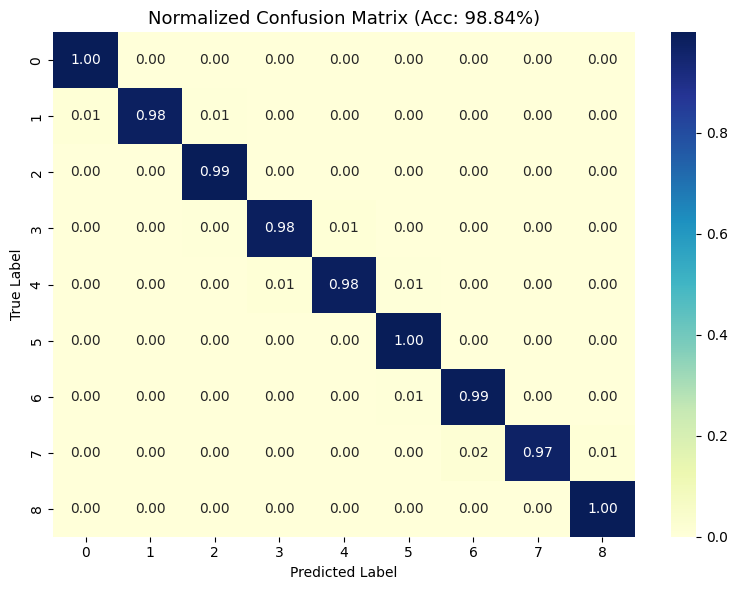

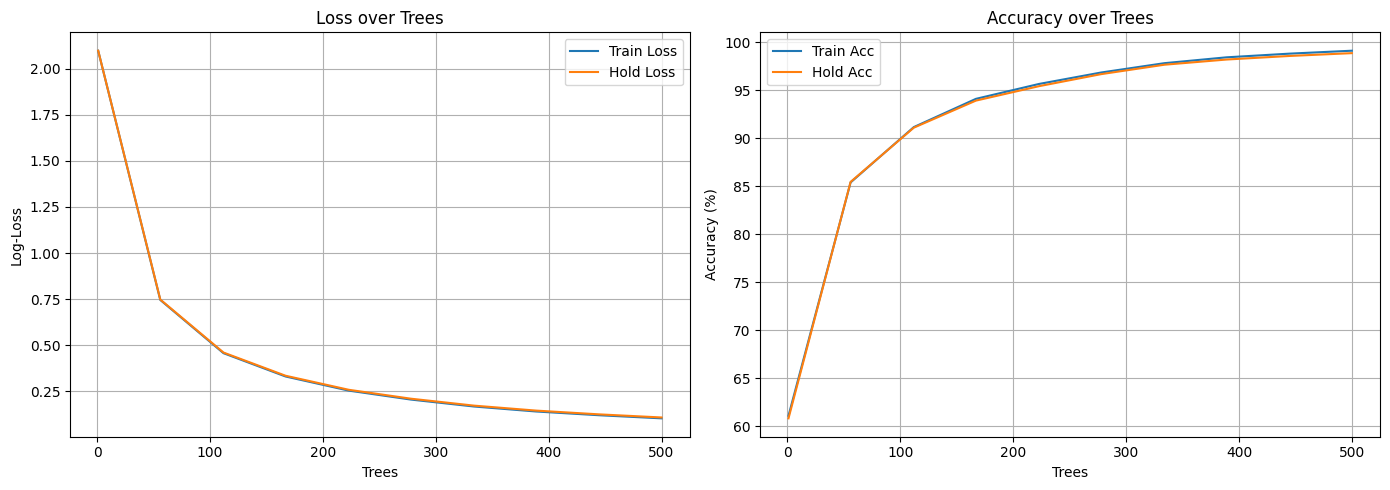


✅ Final Hold Accuracy: 98.84%
✅ Final Train Accuracy: 99.10%


In [ ]:
# ============================================================
# ✅ FINAL - CatBoost with DAE embeddings (Stable + Compatible)
# ============================================================

import os, joblib, random, numpy as np, pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, log_loss
from catboost import CatBoostClassifier, Pool
import matplotlib.pyplot as plt
import seaborn as sns  # 🔹 Added for colored confusion matrix

# ============================================================
# 1️⃣ CONFIGURATION
# ============================================================
DATA_PATH = "/content/data_balanced.csv"
DAE_EMB_FILE = "dae_embeddings.npy"   # must exist
TRAIN_IDX_FILE = "train_idx.npy"
HOLD_IDX_FILE = "hold_idx.npy"
MODEL_OUT = "catboost_repro_fixed.cbm"
RANDOM_SEED = 42
USE_GPU = os.path.exists("/usr/local/cuda")
N_SNAPSHOTS = 10

# ============================================================
# 2️⃣ LOAD DATA + EMBEDDINGS
# ============================================================
if not os.path.exists(DATA_PATH): raise FileNotFoundError(DATA_PATH)
if not os.path.exists(DAE_EMB_FILE): raise FileNotFoundError(DAE_EMB_FILE)

df = pd.read_csv(DATA_PATH)
for c in ["Prediction", "prediction", "Label", "label"]:
    if c in df.columns: df = df.drop(columns=[c])
if "Threats" not in df.columns: raise KeyError("'Threats' column missing")

y = LabelEncoder().fit_transform(df["Threats"].astype(str))
X_base = df.drop(columns=["Threats"]).reset_index(drop=True)

dae_emb = np.load(DAE_EMB_FILE)
emb_df = pd.DataFrame(dae_emb, columns=[f"DAE_{i}" for i in range(dae_emb.shape[1])])
X = pd.concat([X_base, emb_df], axis=1).fillna(0)

# ============================================================
# 3️⃣ TRAIN / HOLD SPLIT (DETERMINISTIC)
# ============================================================
if os.path.exists(TRAIN_IDX_FILE) and os.path.exists(HOLD_IDX_FILE):
    train_idx = np.load(TRAIN_IDX_FILE)
    hold_idx = np.load(HOLD_IDX_FILE)
else:
    idx = np.arange(len(X))
    train_idx, hold_idx = train_test_split(idx, test_size=0.20, stratify=y, random_state=RANDOM_SEED)
    np.save(TRAIN_IDX_FILE, train_idx); np.save(HOLD_IDX_FILE, hold_idx)

X_train, X_hold = X.iloc[train_idx], X.iloc[hold_idx]
y_train, y_hold = y[train_idx], y[hold_idx]

cat_features = X_train.select_dtypes(include=["object"]).columns.tolist()

# ============================================================
# 4️⃣ TRAIN CATBOOST (NO BOOTSTRAP CONFLICT)
# ============================================================
TRAIN_PARAMS = {
    "iterations": 500,
    "learning_rate": 0.03,
    "depth": 8,
    "l2_leaf_reg": 3.0,
    "bootstrap_type": "No",        # disable bootstrap sampling
    "random_strength": 0.0,
    "task_type": "GPU" if USE_GPU else "CPU",
    "thread_count": -1,
    "random_seed": RANDOM_SEED,
    "eval_metric": "MultiClass",
    "verbose": 200
}

print("Training with params (no bootstrap conflict):")
print({k: TRAIN_PARAMS[k] for k in ("iterations", "learning_rate", "depth", "bootstrap_type")})

pool_tr = Pool(X_train, y_train, cat_features=cat_features)
pool_val = Pool(X_hold, y_hold, cat_features=cat_features)

model = CatBoostClassifier(**TRAIN_PARAMS)
model.fit(pool_tr, eval_set=pool_val, use_best_model=True, early_stopping_rounds=100)

model.save_model(MODEL_OUT)
print(f"\nSaved trained model to: {MODEL_OUT}")

# ============================================================
# 5️⃣ SNAPSHOT EVALUATION (FIXED for all CatBoost versions)
# ============================================================
try:
    n_trees = model.get_tree_count()
except AttributeError:
    n_trees = getattr(model, "tree_count_", TRAIN_PARAMS["iterations"])
    print(f"⚠️  get_tree_count() unavailable — using fallback n_trees={n_trees}")

if n_trees <= 0:
    raise RuntimeError("Model has 0 trees (unexpected).")

print(f"Model has {n_trees} trees. Evaluating {N_SNAPSHOTS} checkpoints...")

snap_iters = sorted(set([max(1, int(round(i))) for i in np.linspace(1, n_trees, min(N_SNAPSHOTS, n_trees))]))
if snap_iters[-1] != n_trees:
    snap_iters.append(n_trees)

train_losses, hold_losses, train_accs, hold_accs = [], [], [], []
pool_train = Pool(X_train, y_train, cat_features=cat_features)
pool_hold = Pool(X_hold, y_hold, cat_features=cat_features)

for it in snap_iters:
    p_train = model.predict_proba(pool_train, ntree_end=it)
    p_hold = model.predict_proba(pool_hold, ntree_end=it)
    tr_loss = log_loss(y_train, p_train, labels=sorted(np.unique(y_train)))
    ho_loss = log_loss(y_hold, p_hold, labels=sorted(np.unique(y_train)))
    tr_pred = np.argmax(p_train, axis=1)
    ho_pred = np.argmax(p_hold, axis=1)
    train_losses.append(tr_loss)
    hold_losses.append(ho_loss)
    train_accs.append(accuracy_score(y_train, tr_pred))
    hold_accs.append(accuracy_score(y_hold, ho_pred))
    print(f"trees={it:4d} | train_loss={tr_loss:.4f} | hold_loss={ho_loss:.4f} "
          f"| train_acc={train_accs[-1]*100:5.2f}% | hold_acc={hold_accs[-1]*100:5.2f}%")

# ============================================================
# 6️⃣ FINAL METRICS + PLOTS (with Colored Confusion Matrix)
# ============================================================
final_preds = model.predict(X_hold)
acc = accuracy_score(y_hold, final_preds)
f1 = f1_score(y_hold, final_preds, average='macro')

print("\nFinal Holdout Results:")
print(f"Accuracy: {acc*100:.2f}%")
print(f"Macro-F1: {f1:.4f}")
print("\nClassification Report:\n", classification_report(y_hold, final_preds, digits=4))

# 🔹 Confusion Matrix with color and normalization
cm = confusion_matrix(y_hold, final_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8,6))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="YlGnBu",
            xticklabels=np.unique(y_hold),
            yticklabels=np.unique(y_hold))
plt.title(f"Normalized Confusion Matrix (Acc: {acc*100:.2f}%)", fontsize=13)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# 🔹 Loss and Accuracy curves
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(snap_iters, train_losses, label="Train Loss")
plt.plot(snap_iters, hold_losses, label="Hold Loss")
plt.title("Loss over Trees")
plt.xlabel("Trees"); plt.ylabel("Log-Loss")
plt.legend(); plt.grid(True)

plt.subplot(1,2,2)
plt.plot(snap_iters, np.array(train_accs)*100, label="Train Acc")
plt.plot(snap_iters, np.array(hold_accs)*100, label="Hold Acc")
plt.title("Accuracy over Trees")
plt.xlabel("Trees"); plt.ylabel("Accuracy (%)")
plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

print(f"\n✅ Final Hold Accuracy: {hold_accs[-1]*100:.2f}%")
print(f"✅ Final Train Accuracy: {train_accs[-1]*100:.2f}%")


In [ ]:
def catboost_opinion(df_input):

    import pandas as pd
    import numpy as np
    from catboost import CatBoostClassifier, Pool
    import joblib

    # Load trained CatBoost model and categorical features list
    model = CatBoostClassifier()
    model.load_model("catboost_attack_classifier.cbm")
    cat_features = joblib.load("catboost_cat_features.joblib")

    # Copy input to avoid modifying the original dataframe
    df = df_input.copy()


    # Create CatBoost Pool for prediction
    new_pool = Pool(df, cat_features=[col for col in cat_features if col in df.columns])

    # Predict class and probability
    y_pred = model.predict(new_pool)
    y_pred_proba = model.predict_proba(new_pool)

    # Prepare result dataframe
    result = df.copy()
    result['Predicted_Threat'] = y_pred
    result['Confidence'] = np.max(y_pred_proba, axis=1)

    return result


In [ ]:
df_now = df_normal.head(100)

In [ ]:
check_cat = preprocessing(df_now)

Index(['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress',
       'Threats', 'Prediction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 149043 to 149142
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Time           100 non-null    float64
 1   Protcol        100 non-null    int64  
 2   Flag           100 non-null    int64  
 3   Family         100 non-null    int64  
 4   Clusters       100 non-null    float64
 5   SeddAddress    100 non-null    int64  
 6   ExpAddress     100 non-null    int64  
 7   BTC            100 non-null    float64
 8   USD            100 non-null    float64
 9   Netflow_Bytes  100 non-null    float64
 10  IPaddress      100 non-null    int64  
 11  Threats        100 non-null    int64  
 12  Port           100 non-null    float64
 13  Prediction     100 non-null    int64  
dtypes: float64(6), int64(8)
memory usage: 11.7 KB
None

In [ ]:
check_cat

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
149043,2318.019030,0,2,0,3.0,0,0,0.0,0.0,0.0,0,0,0.0,0
149044,0.000000,2,0,0,3.0,1,25,0.0,0.0,0.0,1,0,443.0,0
149045,1501.022267,1,2,0,3.0,2,25,0.0,0.0,0.0,2,0,443.0,0
149046,783.037846,1,0,0,1.0,2,25,0.0,0.0,0.0,2,0,443.0,0
149047,109.982108,1,1,0,2.0,3,25,0.0,0.0,0.0,3,0,443.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149138,109.969872,1,2,0,3.0,26,38,0.0,0.0,0.0,26,0,54088.0,0
149139,0.789801,1,0,0,1.0,26,38,0.0,0.0,0.0,26,0,58821.0,0
149140,918.230271,0,2,0,1.0,26,39,0.0,0.0,0.0,26,0,51651.0,0
149141,120.407350,2,2,0,2.0,26,40,0.0,0.0,0.0,26,0,55945.0,0


In [ ]:
check_cat = check_cat.drop(columns=['Threats'])

In [ ]:
result = catboost_opinion(check_cat)

In [ ]:
result

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Port,Prediction,Predicted_Threat,Confidence
149043,2318.019030,0,2,0,3.0,0,0,0.0,0.0,0.0,0,0.0,0,3,0.790674
149044,0.000000,2,0,0,3.0,1,25,0.0,0.0,0.0,1,443.0,0,7,0.283030
149045,1501.022267,1,2,0,3.0,2,25,0.0,0.0,0.0,2,443.0,0,7,0.519697
149046,783.037846,1,0,0,1.0,2,25,0.0,0.0,0.0,2,443.0,0,5,0.307001
149047,109.982108,1,1,0,2.0,3,25,0.0,0.0,0.0,3,443.0,0,6,0.459915
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149138,109.969872,1,2,0,3.0,26,38,0.0,0.0,0.0,26,54088.0,0,6,0.795123
149139,0.789801,1,0,0,1.0,26,38,0.0,0.0,0.0,26,58821.0,0,1,0.326775
149140,918.230271,0,2,0,1.0,26,39,0.0,0.0,0.0,26,51651.0,0,7,0.438200
149141,120.407350,2,2,0,2.0,26,40,0.0,0.0,0.0,26,55945.0,0,6,0.823205


In [ ]:
df = pd.read_csv("/content/finale_updated.csv")

In [ ]:
df_sample = df.sample(n=15, random_state=42).reset_index(drop=True)

In [ ]:
df_sample.shape

(15, 14)

In [ ]:
# ===============================================================
# 🔰 IMPORTS
# ===============================================================
import numpy as np
import pandas as pd
from pathlib import Path
import joblib, torch
from catboost import CatBoostClassifier, Pool
from tensorflow.keras.models import load_model
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.losses import MeanSquaredError
from sklearn.preprocessing import StandardScaler

# ===============================================================
# 🔰 MODEL LOADING
# ===============================================================
# --- Autoencoder ---
autoencoder = load_model(
    "/content/deep_autoencoder_model.h5",
    custom_objects={"mse": MeanSquaredError()}
)

# --- CRN Model ---
meta = joblib.load("/content/models/crn_meta.pkl")
scaler_crn = joblib.load("/content/models/crn_scaler.pkl")

crn = LSTM_CRN(input_dim=meta['input_dim'], hidden=256)
crn.load_state_dict(torch.load("/content/models/crn_final.pth"))
crn.eval()

# ===============================================================
# ✅ DEVICE MANAGEMENT
# ===============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
crn.to(device)
print(f"🚀 Using device: {device}")

# --- CatBoost Model ---
model_path = "/content/catboost_attack_classifier.cbm"
cat_model = CatBoostClassifier()
cat_model.load_model(model_path)
cat_features = joblib.load("/content/catboost_cat_features.joblib")
feature_names = joblib.load("/content/catboost_feature_names.joblib")

print("✅ All models loaded successfully.")

# ===============================================================
# 🔰 THREAT MAPPING + CENTROID CALCULATION
# ===============================================================
threat_mapping = {
    0: 'Blacklist', 1: 'Botnet', 2: 'DoS', 3: 'NerisBotnet',
    4: 'Port Scanning', 5: 'SSH', 6: 'Scan', 7: 'Spam',
    8: 'UDP Scan', 9: 'nan'
}

🚀 Using device: cuda
✅ All models loaded successfully.


In [ ]:
autoencoder

<Functional name=functional_3, built=True>

In [ ]:
crn

LSTM_CRN(
  (lstm): LSTM(14, 256, batch_first=True)
  (fc): Linear(in_features=256, out_features=14, bias=True)
)

In [ ]:
dae_threshold

np.float64(0.0015231891408088397)

In [ ]:
crn_threshold

np.float64(2.9761438638765036)

In [ ]:
def is_anomalous(packet_features, seq_len=10, use_crn=True):
    # ✅ Step 1: Remove any unknown columns
    expected_cols = scaler.feature_names_in_
    extra_cols = [c for c in packet_features.columns if c not in expected_cols]
    if extra_cols:
        print(f"⚠️ Dropping unseen columns: {extra_cols}")
        packet_features = packet_features.drop(columns=extra_cols)

    # ✅ Step 2: Reorder to match training feature order
    packet_features = packet_features[expected_cols]

    # ✅ Step 3: Scale data
    packet_scaled = scaler.transform(packet_features)

    # --- DAE opinion ---
    reconstructed_dae = autoencoder.predict(packet_scaled)
    mse_dae = np.mean((packet_scaled - reconstructed_dae)**2, axis=1)
    dae_flags = mse_dae > dae_threshold

    # --- CRN opinion ---
    if use_crn:
        crn_results = crn_opinion_all(packet_scaled, seq_len=seq_len)
        crn_flags = crn_results['Verdict'].values == 'Anomalous'
        if len(crn_flags) < len(dae_flags):
            crn_flags = np.pad(crn_flags, (len(dae_flags)-len(crn_flags), 0),
                               'constant', constant_values=False)
    else:
        crn_flags = np.zeros_like(dae_flags, dtype=bool)

    # --- Combine opinions ---
    combined_flags = dae_flags | crn_flags
    return combined_flags


In [ ]:
df_sample_preproc = preprocessing(df_sample)

/tmp/ipython-input-2619579176.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Threats'] = data['Threats'].str.replace('Bonet', 'Botnet')
/tmp/ipython-input-2619579176.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[feat] = le.fit_transform(data[feat].astype(str))
/tmp/ipython-input-2619579176.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http

Index(['Protcol', 'Flag', 'Family', 'SeddAddress', 'ExpAddress', 'IPaddress',
       'Threats', 'Prediction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
Index: 177201 entries, 0 to 182864
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Time           177201 non-null  float64
 1   Protcol        177201 non-null  int64  
 2   Flag           177201 non-null  int64  
 3   Family         177201 non-null  int64  
 4   Clusters       168638 non-null  float64
 5   SeddAddress    177201 non-null  int64  
 6   ExpAddress     177201 non-null  int64  
 7   BTC            168638 non-null  float64
 8   USD            168638 non-null  float64
 9   Netflow_Bytes  168638 non-null  float64
 10  IPaddress      177201 non-null  int64  
 11  Threats        177201 non-null  int64  
 12  Port           168638 non-null  float64
 13  Prediction     177201 non-null  int64  
dtypes: float64(6), int64(8)
memory usage

/tmp/ipython-input-2619579176.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[feat] = le.fit_transform(data[feat].astype(str))
/tmp/ipython-input-2619579176.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[feat] = le.fit_transform(data[feat].astype(str))
/tmp/ipython-input-2619579176.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas

In [ ]:
# df_sample_preproc = df_sample_preproc.drop(columns=['Prediction'])

In [ ]:
df_sample_preproc.columns

Index(['Time', 'Protcol', 'Flag', 'Family', 'Clusters', 'SeddAddress',
       'ExpAddress', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats',
       'Port', 'Prediction'],
      dtype='object')

In [ ]:
scaler = StandardScaler()
scaler.fit(df_sample_preproc)

StandardScaler()

In [ ]:
expected_cols = scaler.feature_names_in_

In [ ]:
expected_cols

array(['Time', 'Protcol', 'Flag', 'Family', 'Clusters', 'SeddAddress',
       'ExpAddress', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress',
       'Threats', 'Port', 'Prediction'], dtype=object)

In [ ]:
answer = is_anomalous(df_sample_preproc)

5538/5538 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step


ValueError: Per-column arrays must each be 1-dimensional

In [ ]:
answer

array([ True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True])

In [ ]:
df_anomalous = df_sample_preproc[answer].reset_index(drop=True)

print(f"Total packets: {len(df_sample_preproc)}")
print(f"Anomalous packets: {len(df_anomalous)}")

Total packets: 15
Anomalous packets: 14


In [ ]:
df_anomalous

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,32.000000,0,1,2,1.0,1,3,30.0,199.0,1583.0,4,3,5068.0,3
1,28.000000,0,2,0,2.0,1,3,19.0,853.0,550.0,4,5,5062.0,0
2,20.000000,0,3,6,2.0,1,3,2.0,63.0,7804.0,3,5,5061.0,0
3,51.000000,0,1,4,2.0,4,3,2.0,3034.0,148.0,2,4,5068.0,0
4,6.000000,1,4,7,2.0,1,3,8.0,942.0,120.0,2,3,5062.0,3
5,58.000000,2,1,5,3.0,1,3,30.0,4321.0,636.0,2,5,5066.0,3
6,55.000000,1,3,0,1.0,3,2,2.0,9464.0,1221.0,4,1,5062.0,0
7,1780.662935,2,7,8,2.0,0,1,0.0,0.0,0.0,0,7,443.0,1
8,29.000000,1,3,3,2.0,4,0,4.0,1147.0,3816.0,5,6,5062.0,0
9,41.000000,1,1,3,2.0,1,2,22.0,850.0,753.0,3,1,5061.0,0


In [ ]:
X_train

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Port,Prediction
220307,53.630134,0,8,NaN,1.076147,NaN,NaN,265.455305,20339.918408,137.209069,NaN,5067.770237,NaN
44590,3.000000,2,6,0.0,1.000000,0.0,4.0,5.000000,405.000000,217.000000,0.0,5066.000000,2.0
96185,16.000000,0,8,11.0,1.000000,5.0,6.0,22.000000,21128.000000,3926.000000,2.0,5062.000000,1.0
162090,18.699415,0,5,NaN,1.026681,NaN,NaN,-0.089832,6201.065984,472.415637,NaN,5065.975292,NaN
26878,50.000000,1,4,8.0,1.000000,5.0,6.0,13.000000,18454.000000,36.000000,0.0,5066.000000,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2611,11.000000,2,1,5.0,3.000000,0.0,4.0,30.000000,126227.000000,330.000000,2.0,5068.000000,1.0
1831,25.000000,0,8,1.0,1.000000,5.0,6.0,22.000000,18210.000000,4486.000000,2.0,5062.000000,1.0
34283,20.000000,0,4,7.0,2.000000,0.0,4.0,180.000000,241.000000,330.000000,1.0,5061.000000,1.0
189745,7.164356,0,1,NaN,1.001267,NaN,NaN,2.052890,18846.874684,3293.475046,NaN,5060.726260,NaN


In [ ]:
y_train

,Threats
220307,3
44590,2
96185,7
162090,1
26878,0
...,...
2611,8
1831,0
34283,5
189745,2


In [ ]:
import numpy as np
import pandas as pd

# --- Threat label mapping ---
threat_mapping = {
    0: 'Blacklist', 1: 'Botnet', 2: 'DoS', 3: 'NerisBotnet',
    4: 'Port Scanning', 5: 'SSH', 6: 'Scan', 7: 'Spam',
    8: 'UDP Scan', 9: 'nan'
}

# --- Ensure X_train is numeric ---
X_train_num = X_train.copy()

# Convert categorical/object columns to numeric codes
for col in X_train_num.select_dtypes(include=['object']).columns:
    X_train_num[col] = X_train_num[col].astype('category').cat.codes

# Fill NaNs with 0 to avoid invalid distance computation
X_train_num = X_train_num.fillna(0)

# --- Step 1: Compute centroids per class ---
centroids = {}
for lbl in np.unique(y_train):
    centroids[lbl] = X_train_num[y_train == lbl].mean(axis=0)

print(f"\n✅ Computed centroids for {len(centroids)} classes:\n")
for lbl, center in centroids.items():
    print(f"Class {lbl} ({threat_mapping.get(lbl, 'Unknown')}): centroid shape = {center.shape}")

# --- Step 2: Compute distance threshold ---
all_distances = []
for lbl in np.unique(y_train):
    X_lbl = X_train_num[y_train == lbl].values
    centroid = centroids[lbl].values
    distances = np.linalg.norm(X_lbl - centroid, axis=1)
    all_distances.extend(distances)

threshold = np.percentile(all_distances, 95)
print(f"\n✅ Computed centroid threshold = {threshold:.4f}")



✅ Computed centroids for 9 classes:

Class 0 (Blacklist): centroid shape = (13,)
Class 1 (Botnet): centroid shape = (13,)
Class 2 (DoS): centroid shape = (13,)
Class 3 (NerisBotnet): centroid shape = (13,)
Class 4 (Port Scanning): centroid shape = (13,)
Class 5 (SSH): centroid shape = (13,)
Class 6 (Scan): centroid shape = (13,)
Class 7 (Spam): centroid shape = (13,)
Class 8 (UDP Scan): centroid shape = (13,)

✅ Computed centroid threshold = 39234.7342


In [ ]:

# ===============================================================
# (B) Zero-Day Detection Function
# ===============================================================
def classify_packets_catboost(df_packets, prob_threshold=0.6):
    """
    df_packets: DataFrame of new/preprocessed traffic samples
    prob_threshold: minimum confidence to classify as 'Known'
    """
    # --- Align input columns ---
    df_packets = df_packets.reindex(columns=feature_names, fill_value=0)

    # --- CatBoost Pool for prediction ---
    pool = Pool(df_packets, cat_features=cat_features)

    # --- Get class probabilities ---
    probs = model.predict_proba(pool)
    preds = np.argmax(probs, axis=1)
    confs = np.max(probs, axis=1)
    pred_labels = [model.classes_[i] for i in preds]

    # --- Convert to numeric for centroid distance computation ---
    df_numeric = df_packets.copy()
    for col in cat_features:
        df_numeric[col] = df_numeric[col].astype("category").cat.codes
    df_numeric = df_numeric.fillna(0).values

    results = []
    for i, (feat_vec, pred_label, conf) in enumerate(zip(df_numeric, pred_labels, confs)):
        # Compute distance to all centroids
        dists = {lbl: np.linalg.norm(feat_vec - c) for lbl, c in centroids.items()}
        nearest_lbl = min(dists, key=dists.get)
        min_dist = dists[nearest_lbl]

        # Classification logic
        if conf > prob_threshold and min_dist < threshold:
            verdict = f"✅ Known Attack: {pred_label}"
        else:
            verdict = f"⚠️ Zero-Day / Unknown — Top={pred_label}, Nearest={nearest_lbl}"

        results.append({
            "predicted_label": pred_label,
            "confidence": conf,
            "nearest_class": nearest_lbl,
            "distance_to_nearest": round(min_dist, 4),
            "verdict": verdict
        })

    return pd.DataFrame(results)





In [ ]:
df_anomalous

,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,32.000000,0,1,2,1.0,1,3,30.0,199.0,1583.0,4,3,5068.0,3
1,28.000000,0,2,0,2.0,1,3,19.0,853.0,550.0,4,5,5062.0,0
2,20.000000,0,3,6,2.0,1,3,2.0,63.0,7804.0,3,5,5061.0,0
3,51.000000,0,1,4,2.0,4,3,2.0,3034.0,148.0,2,4,5068.0,0
4,6.000000,1,4,7,2.0,1,3,8.0,942.0,120.0,2,3,5062.0,3
5,58.000000,2,1,5,3.0,1,3,30.0,4321.0,636.0,2,5,5066.0,3
6,55.000000,1,3,0,1.0,3,2,2.0,9464.0,1221.0,4,1,5062.0,0
7,1780.662935,2,7,8,2.0,0,1,0.0,0.0,0.0,0,7,443.0,1
8,29.000000,1,3,3,2.0,4,0,4.0,1147.0,3816.0,5,6,5062.0,0
9,41.000000,1,1,3,2.0,1,2,22.0,850.0,753.0,3,1,5061.0,0


In [ ]:
df_results = classify_packets_catboost(df_anomalous, prob_threshold=0.6)

In [ ]:
df_results

,predicted_label,confidence,nearest_class,distance_to_nearest,verdict
0,8,0.471001,2,4951.5668,"⚠️ Zero-Day / Unknown — Top=8, Nearest=2"
1,7,0.789428,2,4576.7357,✅ Known Attack: 7
2,7,0.497474,2,7511.3732,"⚠️ Zero-Day / Unknown — Top=7, Nearest=2"
3,6,0.789493,2,2944.0166,✅ Known Attack: 6
4,5,0.687454,2,4672.7083,✅ Known Attack: 5
5,7,0.538309,2,1785.0056,"⚠️ Zero-Day / Unknown — Top=7, Nearest=2"
6,1,0.948860,5,660.1722,✅ Known Attack: 1
7,8,0.544270,2,7453.7674,"⚠️ Zero-Day / Unknown — Top=8, Nearest=2"
8,5,0.601231,2,4262.7967,✅ Known Attack: 5
9,1,0.578405,2,4508.6811,"⚠️ Zero-Day / Unknown — Top=1, Nearest=2"


In [ ]:
# Print only the first three columns
print(df_results.iloc[:, :3])


    predicted_label  confidence  nearest_class
0                 8    0.471001              2
1                 7    0.789428              2
2                 7    0.497474              2
3                 6    0.789493              2
4                 5    0.687454              2
5                 7    0.538309              2
6                 1    0.948860              5
7                 8    0.544270              2
8                 5    0.601231              2
9                 1    0.578405              2
10                7    0.789841              0
11                2    0.992349              2
12                1    0.312093              2
13                0    0.563406              0


In [ ]:
# ===============================================================
# 🔰 IMPORTS
# ===============================================================
import numpy as np
import pandas as pd
import joblib, torch
from pathlib import Path
from catboost import CatBoostClassifier, Pool
from tensorflow.keras.models import load_model
from tensorflow.keras.losses import MeanSquaredError
from sklearn.preprocessing import StandardScaler

# ===============================================================
# 🔰 DEVICE SETUP
# ===============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ===============================================================
# 🔰 MODEL LOADING
# ===============================================================
# Autoencoder
autoencoder = load_model("/content/deep_autoencoder_model.h5",
                         custom_objects={"mse": MeanSquaredError()})

# CRN
meta = joblib.load("/content/models/crn_meta.pkl")
scaler_crn = joblib.load("/content/models/crn_scaler.pkl")
crn = LSTM_CRN(input_dim=meta['input_dim'], hidden=256)
crn.load_state_dict(torch.load("/content/models/crn_final.pth", map_location=device))
crn.to(device)
crn.eval()

# CatBoost
cat_model = CatBoostClassifier()
cat_model.load_model("/content/catboost_attack_classifier.cbm")
cat_features = joblib.load("/content/catboost_cat_features.joblib")
feature_names = joblib.load("/content/catboost_feature_names.joblib")

print("✅ All models loaded successfully.")

# ===============================================================
# 🔰 THREAT MAPPING
# ===============================================================
threat_mapping = {
    0: 'Blacklist', 1: 'Botnet', 2: 'DoS', 3: 'NerisBotnet',
    4: 'Port Scanning', 5: 'SSH', 6: 'Scan', 7: 'Spam',
    8: 'UDP Scan', 9: 'nan'
}

# --- Thresholds for anomaly detection ---
dae_threshold = np.float64(0.0015231891408088397)
crn_threshold = np.float64(2.9761438638765036)

# ===============================================================
# 🔰 CENTROIDS
# ===============================================================
def compute_centroids(X_train, y_train):
    X_train_num = X_train.copy()
    for col in X_train_num.select_dtypes(include=['object']).columns:
        X_train_num[col] = X_train_num[col].astype('category').cat.codes
    X_train_num = X_train_num.fillna(0)

    centroids = {}
    for lbl in np.unique(y_train):
        centroids[lbl] = X_train_num[y_train == lbl].mean(axis=0)

    all_distances = []
    for lbl in np.unique(y_train):
        X_lbl = X_train_num[y_train == lbl].values
        centroid = centroids[lbl].values
        distances = np.linalg.norm(X_lbl - centroid, axis=1)
        all_distances.extend(distances)
    threshold = np.percentile(all_distances, 95)
    return centroids, threshold

# ===============================================================
# 🔰 ANOMALY DETECTION
# ===============================================================
def crn_opinion_all(X_scaled, seq_len=10):
    """Batch evaluation using CRN."""
    with torch.no_grad():
        X_tensor = torch.tensor(X_scaled, dtype=torch.float32).to(device)
        output = crn(X_tensor.unsqueeze(1))
        preds = (output.squeeze() > 0.5).cpu().numpy().ravel()  # <-- ravel ensures 1D
    verdict = np.where(preds, "Anomalous", "Normal")
    return pd.DataFrame({"Verdict": verdict})

def is_anomalous(packet_features, scaler, dae_threshold, seq_len=10, use_crn=True):
    """Detect anomalous packets using DAE + CRN."""
    expected_cols = scaler.feature_names_in_
    packet_features = packet_features.reindex(columns=expected_cols, fill_value=0)
    packet_scaled = scaler.transform(packet_features)

    # DAE opinion
    reconstructed = autoencoder.predict(packet_scaled)
    mse = np.mean((packet_scaled - reconstructed)**2, axis=1)
    dae_flags = mse > dae_threshold

    # CRN opinion
    # --- CRN opinion
    if use_crn:
        crn_results = crn_opinion_all(packet_scaled, seq_len=seq_len)
        crn_flags = crn_results['Verdict'].values == 'Anomalous'
        # Align length: pad with False at the beginning if shorter
        if len(crn_flags) < len(dae_flags):
            pad_len = len(dae_flags) - len(crn_flags)
            crn_flags = np.pad(crn_flags, (pad_len, 0), 'constant', constant_values=False)
        elif len(crn_flags) > len(dae_flags):
            crn_flags = crn_flags[-len(dae_flags):]  # truncate if longer
    else:
        crn_flags = np.zeros_like(dae_flags, dtype=bool)


    return dae_flags | crn_flags

# ===============================================================
# 🔰 CATBOOST CLASSIFICATION / ZERO-DAY
# ===============================================================
def classify_packets_catboost(df_packets, model, centroids, threshold,
                              cat_features, feature_names, prob_threshold=0.6):
    """Classify anomalous packets and flag zero-day samples."""
    df_packets = df_packets.reindex(columns=feature_names, fill_value=0)
    pool = Pool(df_packets, cat_features=cat_features)
    probs = model.predict_proba(pool)
    preds = np.argmax(probs, axis=1)
    confs = np.max(probs, axis=1)
    pred_labels = preds

    df_numeric = df_packets.copy()
    for col in cat_features:
        df_numeric[col] = df_numeric[col].astype("category").cat.codes
    df_numeric = df_numeric.fillna(0).values

    results = []
    for i, (feat_vec, pred_label, conf) in enumerate(zip(df_numeric, pred_labels, confs)):
        dists = {lbl: np.linalg.norm(feat_vec - c) for lbl, c in centroids.items()}
        nearest_lbl = min(dists, key=dists.get)
        min_dist = dists[nearest_lbl]

        if conf > prob_threshold and min_dist < threshold:
            verdict = f"✅ Known Attack: {threat_mapping.get(pred_label, 'Unknown')}"
        else:
            verdict = f"⚠️ Zero-Day / Unknown (Pred={threat_mapping.get(pred_label)}, Nearest={threat_mapping.get(nearest_lbl)})"

        results.append({
            "predicted_label": threat_mapping.get(pred_label, 'Unknown'),
            "confidence": round(conf, 3),
            "nearest_class": threat_mapping.get(nearest_lbl, 'Unknown'),
            "distance": round(min_dist, 4),
            "verdict": verdict
        })
    return pd.DataFrame(results)

# ===============================================================
# 🔰 FULL PIPELINE
# ===============================================================
def full_detection_pipeline(df_sample, scaler, dae_threshold,
                            X_train, y_train, prob_threshold=0.6):
    print("\n🚀 Starting pipeline...")

    # Preprocess
    df_sample_preproc = df_sample.fillna(0)

    # Anomaly Detection
    anomaly_flags = is_anomalous(df_sample_preproc, scaler, dae_threshold)
    df_anomalous = df_sample_preproc[anomaly_flags].reset_index(drop=True)
    print(f"Total packets: {len(df_sample_preproc)} | Anomalous: {len(df_anomalous)}")

    # Compute Centroids
    centroids, threshold = compute_centroids(X_train, y_train)
    print(f"Centroid threshold = {threshold:.4f}")

    # Classification
    df_results = classify_packets_catboost(df_anomalous, cat_model, centroids,
                                           threshold, cat_features, feature_names,
                                           prob_threshold=prob_threshold)
    print("✅ Classification complete.")
    return df_results


df_results = full_detection_pipeline(df_sample_preproc, scaler, dae_threshold, X_train, y_train)
display(df_results.head())

Using device: cuda
✅ All models loaded successfully.


In [ ]:
df_sample_preproc = df_sample_preproc.sample(n=15, random_state=42).reset_index(drop=True)

In [ ]:
df_results = full_detection_pipeline(df_sample_preproc, scaler, dae_threshold, X_train, y_train)
display(df_results.head())


🚀 Starting pipeline...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
Total packets: 15 | Anomalous: 15
Centroid threshold = 39234.7342
✅ Classification complete.


,predicted_label,confidence,nearest_class,distance,verdict
0,SSH,0.941,DoS,5218.4117,✅ Known Attack: SSH
1,Spam,0.998,Spam,2813.5293,✅ Known Attack: Spam
2,Scan,0.697,DoS,4761.3139,✅ Known Attack: Scan
3,SSH,0.524,DoS,57190.8410,"⚠️ Zero-Day / Unknown (Pred=SSH, Nearest=DoS)"
4,Scan,0.831,DoS,3830.5837,✅ Known Attack: Scan


In [ ]:
dae_threshold is np.float64(0.0015231891408088397)

np.float64(0.0015231891408088397)

In [ ]:
crn_threshold is np.float64(2.9761438638765036)

np.float64(2.9761438638765036)